In [1]:
import FinanceDataReader as fdr

# 삼성전자(005930) 과거 주가 전체 조회
df = fdr.DataReader('005930', '1995-01-03')

In [2]:
df

,Open,High,Low,Close,Volume,Change
Date,,,,,,
2014-07-11,26000,26040,25640,25680,215592,NaN
2014-07-14,25960,26000,25720,25720,141643,0.001558
2014-07-15,26000,26459,25940,26400,239521,0.026439
2014-07-16,26259,26459,26220,26420,182284,0.000758
2014-07-17,26519,26700,26400,26600,218454,0.006813
...,...,...,...,...,...,...
2026-09-28,284500,285500,268500,270000,21346064,-0.057592
2026-09-29,266000,276000,266000,275000,15963864,0.018519
2026-09-30,274500,276000,267500,269500,16477580,-0.020000


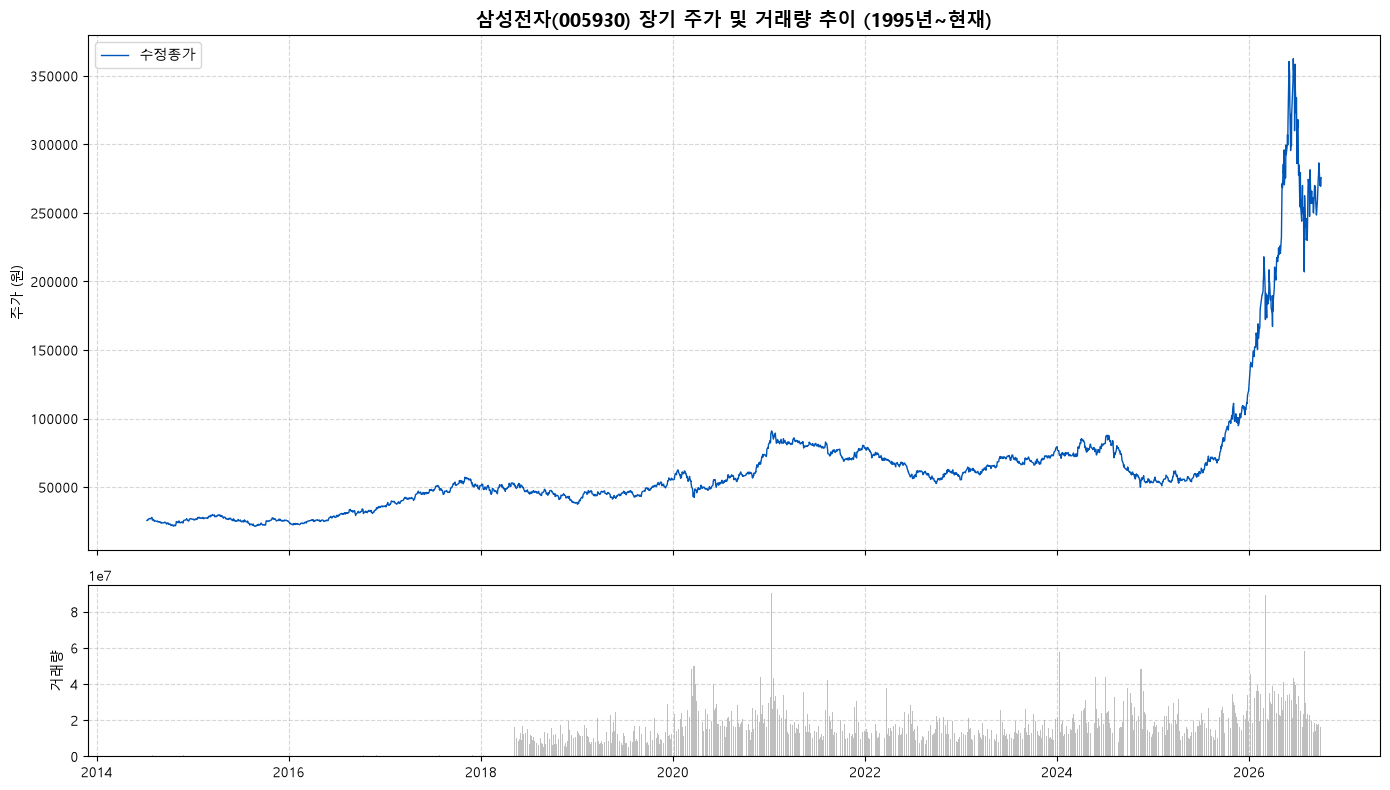

In [3]:
import matplotlib.pyplot as plt
import platform

# OS별 한글 폰트 설정 (깨짐 방지)
if platform.system() == 'Darwin':       # Mac OS
    plt.rc('font', family='AppleGothic')
elif platform.system() == 'Windows':    # Windows OS
    plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

# 차트 틀 생성 (위: 주가, 아래: 거래량)
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(14, 8), 
    sharex=True, 
    gridspec_kw={'height_ratios': [3, 1]}
)

# 1. 상단: 주가(Close) 추이
ax1.plot(df.index, df['Close'], label='수정종가', color='#0055b8', linewidth=1)
ax1.set_title('삼성전자(005930) 장기 주가 및 거래량 추이 (1995년~현재)', fontsize=14, fontweight='bold')
ax1.set_ylabel('주가 (원)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# 2. 하단: 거래량(Volume)
ax2.bar(df.index, df['Volume'], color='gray', alpha=0.5, width=1.0)
ax2.set_ylabel('거래량')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

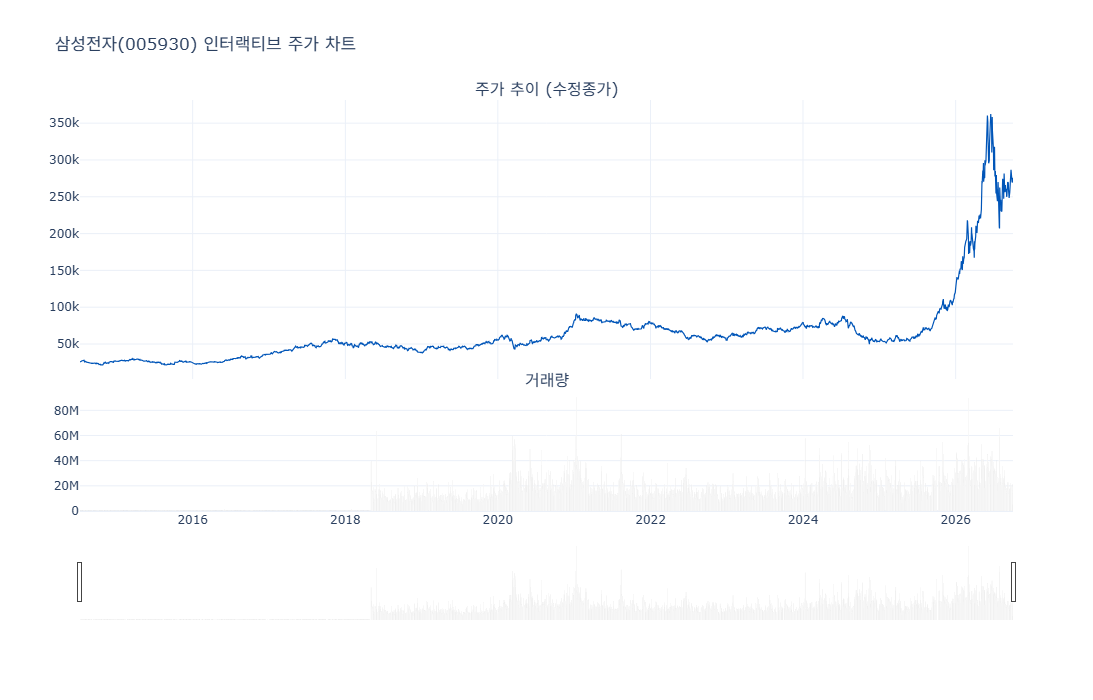

In [4]:
# 라이브러리 미설치 시: !pip install plotly
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 서브플롯 생성 (행 2개, X축 공유)
fig = make_subplots(
    rows=2, cols=1, 
    shared_xaxes=True, 
    vertical_spacing=0.03, 
    subplot_titles=('주가 추이 (수정종가)', '거래량'),
    row_heights=[0.7, 0.3]
)

# 1. 상단: 주가 선 그래프
fig.add_trace(
    go.Scatter(x=df.index, y=df['Close'], name='종가', line=dict(color='#0055b8', width=1.2)),
    row=1, col=1
)

# 2. 하단: 거래량 바 그래프
fig.add_trace(
    go.Bar(x=df.index, y=df['Volume'], name='거래량', marker_color='gray'),
    row=2, col=1
)

# 레이아웃 설정 (하단 범주 선택 슬라이더 추가)
fig.update_layout(
    title_text='삼성전자(005930) 인터랙티브 주가 차트',
    xaxis2_rangeslider_visible=True,  # 하단 기간 선택 슬라이더
    template='plotly_white',
    height=700,
    showlegend=False
)

fig.show()

In [6]:
from dotenv import load_dotenv

load_dotenv()

True

In [7]:
from pykrx import stock

# 삼성전자 일별 OHLCV
df = stock.get_market_ohlcv_by_date("19950103", "20260918", "005930")

# 특정 일자의 전체 종목 PER/PBR 조회
df_fundamental = stock.get_market_fundamental_by_ticker("20260918", market="KOSPI")

KRX 로그인 시도...
  로그인 ID: o3o132
KRX 로그인 완료.
  로그인 시간: 2026-10-02 11:40:27
  만료 시간: 2026-10-02 12:40:27


In [9]:
df

,시가,고가,저가,종가,거래량,등락률
날짜,,,,,,
2014-07-11,26000,26040,25640,25680,215592,NaN
2014-07-14,25960,26000,25720,25720,141643,0.155763
2014-07-15,26000,26459,25940,26400,239521,2.643857
2014-07-16,26259,26459,26220,26420,182284,0.075758
2014-07-17,26519,26700,26400,26600,218454,0.681302
...,...,...,...,...,...,...
2026-09-14,249500,254500,247000,248500,17776098,-4.238921
2026-09-15,248000,252000,246000,250500,11435506,0.804829
2026-09-16,248000,254000,247500,253500,11757106,1.197605


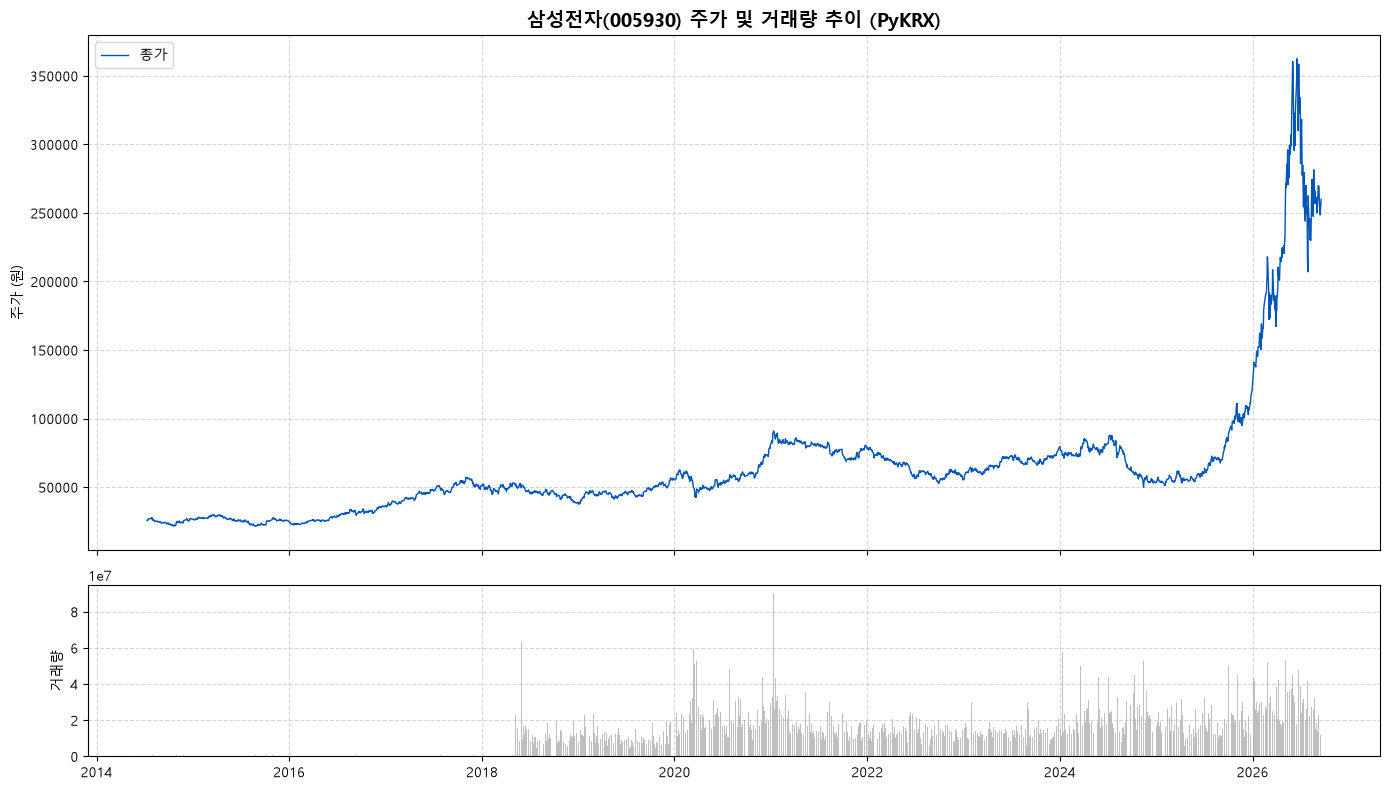

In [10]:
import matplotlib.pyplot as plt
import platform

# OS별 한글 폰트 설정
if platform.system() == 'Darwin':       # Mac OS
    plt.rc('font', family='AppleGothic')
elif platform.system() == 'Windows':    # Windows OS
    plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 차트 레이아웃 생성
fig, (ax1, ax2) = plt.subplots(
    2, 1, 
    figsize=(14, 8), 
    sharex=True, 
    gridspec_kw={'height_ratios': [3, 1]}
)

# 1. 상단: 종가 추이 (PyKRX의 '종가' 컬럼 사용)
ax1.plot(df.index, df['종가'], label='종가', color='#0055b8', linewidth=1)
ax1.set_title('삼성전자(005930) 주가 및 거래량 추이 (PyKRX)', fontsize=14, fontweight='bold')
ax1.set_ylabel('주가 (원)')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# 2. 하단: 거래량 (PyKRX의 '거래량' 컬럼 사용)
ax2.bar(df.index, df['거래량'], color='gray', alpha=0.5, width=1.0)
ax2.set_ylabel('거래량')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 거시지표 - 주가 상관관계 분석 스크립트


✅ [2025-12-01 ~ 2026-09-30] 구간 총 10개 월별 데이터 분석 준비 완료
            samsung_price  usd_krw           fx         cpi        m2
date                                                                 
2025-12-31       119900.0   1434.9  402997391.0  121.177353  172464.1
2026-01-31       160500.0   1427.0  400838028.0  121.799118  172464.1
2026-02-28       216500.0   1424.5  402450277.0  122.378529  172464.1
            samsung_price  usd_krw           fx         cpi        m2
date                                                                 
2026-07-31       262500.0   1441.1  403137505.0  120.898235  172464.1
2026-08-31       260000.0   1376.5  417376851.0  121.754706  172464.1
2026-09-30       269500.0   1380.3  417376851.0  121.754706  172464.1


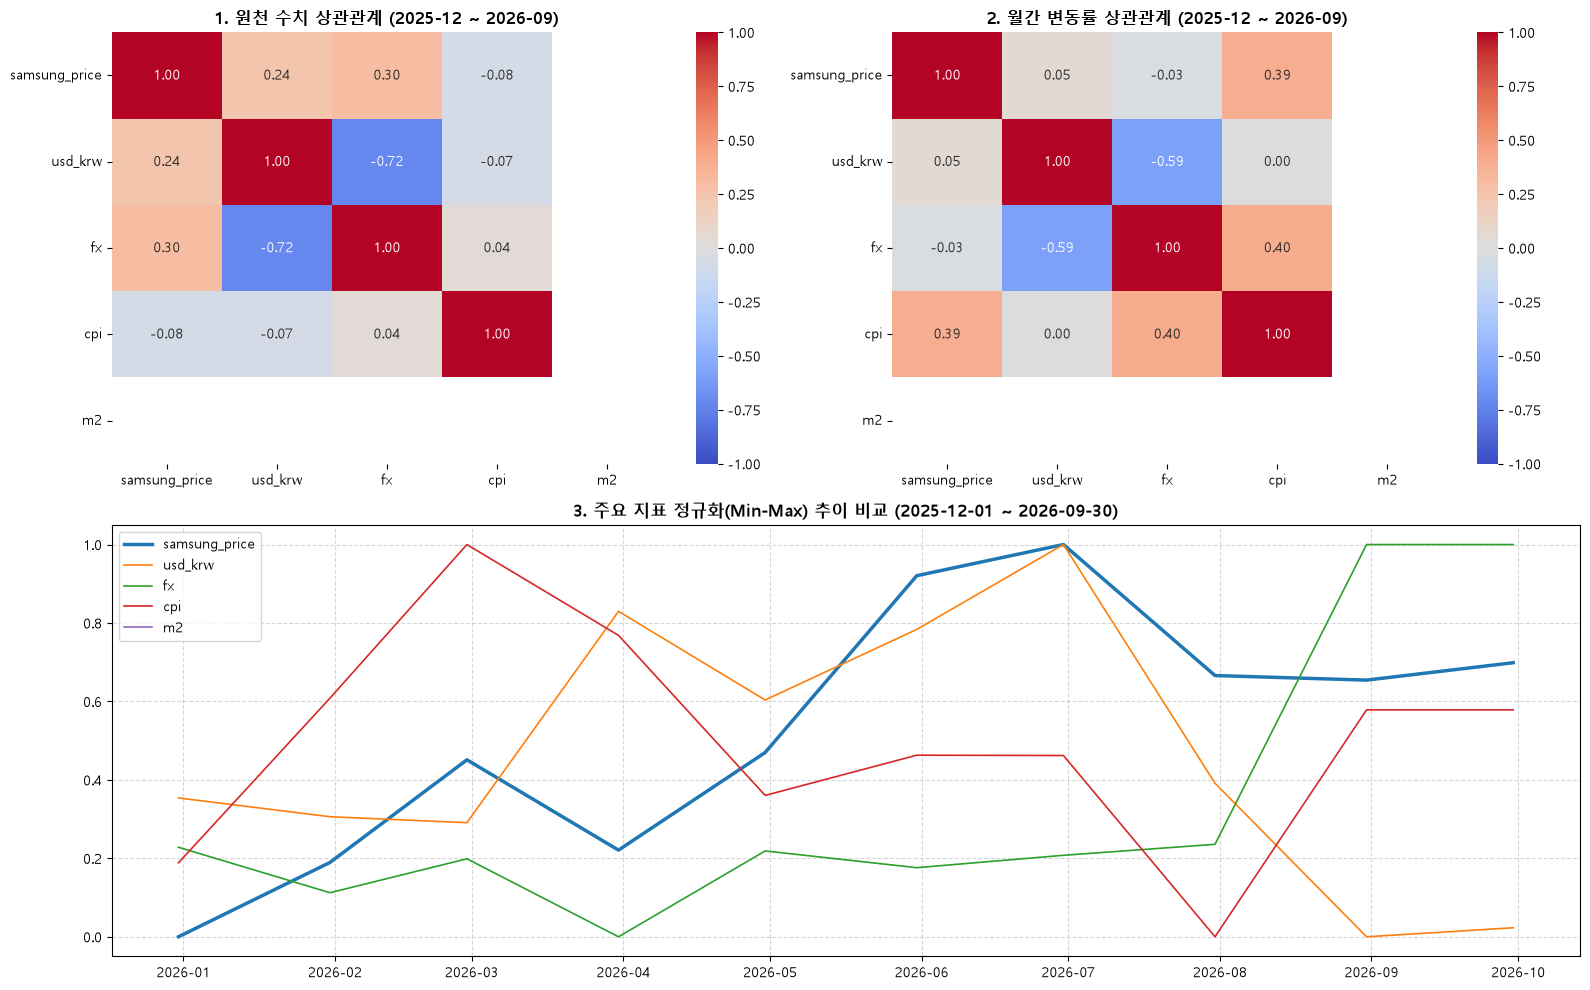

In [23]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import FinanceDataReader as fdr
import platform
from dotenv import load_dotenv
from sqlalchemy import create_engine

# ---------------------------------------------------------
# 1. 🔥 분석할 기간 설정 (여기 날짜를 변경하세요!)
# ---------------------------------------------------------
START_DATE = '2025-12-01'  # 시작일 (YYYY-MM-DD)
END_DATE   = '2026-09-30'  # 종료일 (YYYY-MM-DD)

# ---------------------------------------------------------
# 2. 환경 설정 및 한글 폰트 적용
# ---------------------------------------------------------
load_dotenv()
pd.set_option('future.no_silent_downcasting', True)

if platform.system() == 'Darwin':
    plt.rc('font', family='AppleGothic')
elif platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# ---------------------------------------------------------
# 3. DB 연결 Engine 생성
# ---------------------------------------------------------
db_user = os.getenv("DB_USER", "postgres")
db_pw = os.getenv("DB_PASSWORD")
db_host = os.getenv("DB_HOST", "localhost")
db_port = os.getenv("DB_PORT", "5432")
db_name = os.getenv("DB_NAME", "stock_analysis")

db_url = f"postgresql+psycopg2://{db_user}:{db_pw}@{db_host}:{db_port}/{db_name}"
engine = create_engine(db_url)

# ---------------------------------------------------------
# 4. DB 데이터 로드
# ---------------------------------------------------------
def load_data(query, name):
    try:
        df = pd.read_sql(query, engine, parse_dates=['date'])
        return df
    except Exception as e:
        print(f"❌ [{name}] 불러오기 실패: {e}")
        return pd.DataFrame()

df_krw = load_data("SELECT date, exchange_rate AS usd_krw FROM raw.krw_exchange_rates WHERE item_code = '0000001'", "원/달러 환율")
df_fx = load_data("SELECT date, amount AS usd_krw FROM raw.fx_reserves WHERE item_code = '04'", "외환보유액")
df_ktb = load_data("SELECT date, yield_rate AS ktb_3y FROM raw.ktb_yields WHERE item_code = '0101500'", "국고채 3년")
df_cpi = load_data("SELECT date, cpi_value AS cpi FROM raw.consumer_price_indices", "소비자물가지수(CPI)")
df_m2 = load_data("SELECT date, m2_value AS m2 FROM raw.m2_money_supply", "광의통화(M2)")

# 삼성전자 주가 로드 (시작일보다 약간 여유 있게 수집 후 잘라냄)
df_samsung = fdr.DataReader('005930', '1995-01-01')[['Close']].rename(columns={'Close': 'samsung_price'})
df_samsung.index.name = 'date'

# ---------------------------------------------------------
# 5. 데이터 병합 및 월별(ME) 리샘플링
# ---------------------------------------------------------
dfs_to_concat = {'samsung_price': df_samsung['samsung_price'].resample('ME').last()}

for name, df in [('usd_krw', df_krw), ('fx', df_fx), ('ktb_3y', df_ktb), ('cpi', df_cpi), ('m2', df_m2)]:
    if not df.empty:
        df_clean = df.groupby('date').mean()
        s = df_clean.iloc[:, 0].resample('ME').last()
        dfs_to_concat[name] = s

df_monthly = pd.concat(dfs_to_concat, axis=1).astype(float)
df_monthly = df_monthly.dropna(how='all', axis=1)
df_monthly = df_monthly.bfill().ffill().dropna()

# ---------------------------------------------------------
# 6. 🎯 지정한 기간(START_DATE ~ END_DATE) 데이터 필터링
# ---------------------------------------------------------
df_monthly = df_monthly.loc[START_DATE:END_DATE]

print(f"\n✅ [{START_DATE} ~ {END_DATE}] 구간 총 {len(df_monthly)}개 월별 데이터 분석 준비 완료")
print(df_monthly.head(3))
print(df_monthly.tail(3))

# ---------------------------------------------------------
# 7. 시각화
# ---------------------------------------------------------
if len(df_monthly) > 0:
    corr_level = df_monthly.corr()
    corr_pct = df_monthly.pct_change().dropna().corr()

    fig = plt.figure(figsize=(16, 10))

    # [1] 원천 수치 상관관계 히트맵
    ax1 = fig.add_subplot(2, 2, 1)
    sns.heatmap(corr_level, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=ax1)
    ax1.set_title(f"1. 원천 수치 상관관계 ({START_DATE[:7]} ~ {END_DATE[:7]})", fontsize=12, fontweight='bold')

    # [2] 월간 변동률 상관관계 히트맵
    ax2 = fig.add_subplot(2, 2, 2)
    sns.heatmap(corr_pct, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=ax2)
    ax2.set_title(f"2. 월간 변동률 상관관계 ({START_DATE[:7]} ~ {END_DATE[:7]})", fontsize=12, fontweight='bold')

    # [3] 정규화 추이 차트
    ax3 = fig.add_subplot(2, 1, 2)
    df_norm = (df_monthly - df_monthly.min()) / (df_monthly.max() - df_monthly.min())

    for col in df_norm.columns:
        lw = 2.5 if col == 'samsung_price' else 1.2
        ax3.plot(df_norm.index, df_norm[col], label=col, linewidth=lw)

    ax3.set_title(f"3. 주요 지표 정규화(Min-Max) 추이 비교 ({START_DATE} ~ {END_DATE})", fontsize=12, fontweight='bold')
    ax3.grid(True, linestyle='--', alpha=0.5)
    ax3.legend(loc='upper left')

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ 지정하신 기간 내에 존재하는 데이터가 없습니다. START_DATE와 END_DATE를 확인해주세요.")